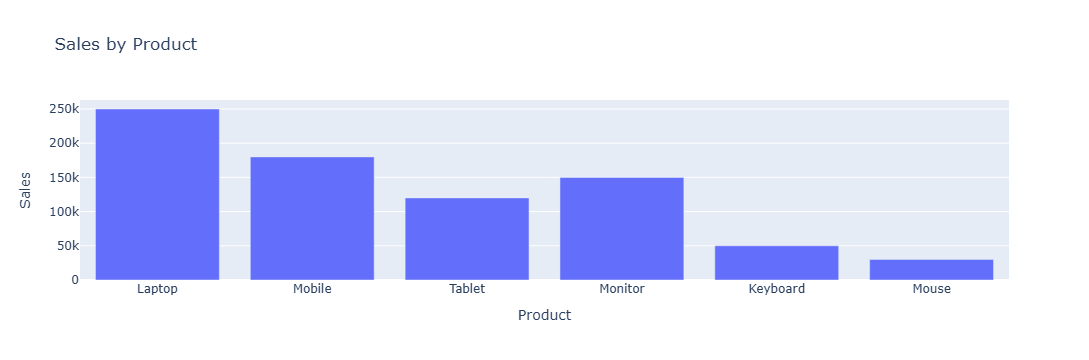

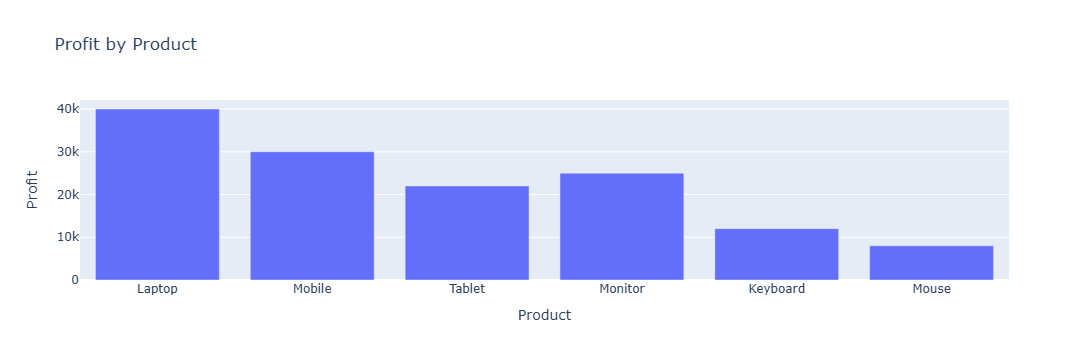

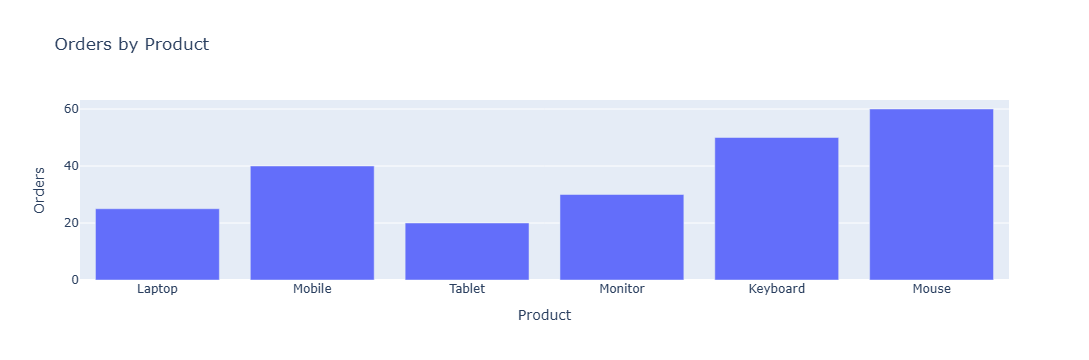

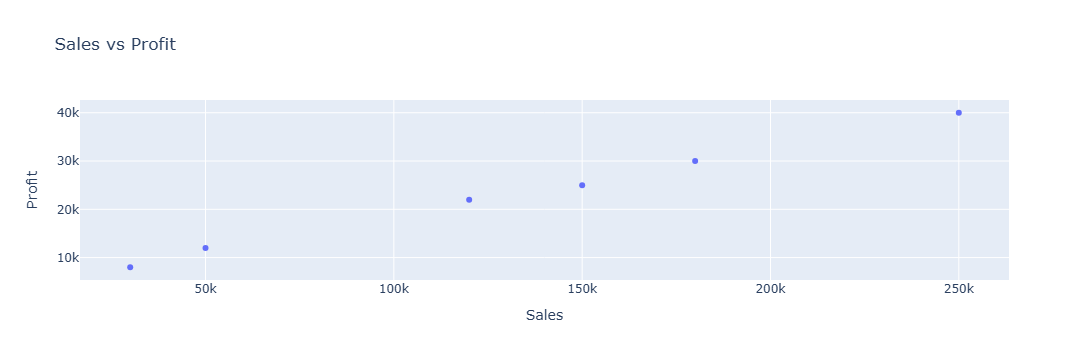

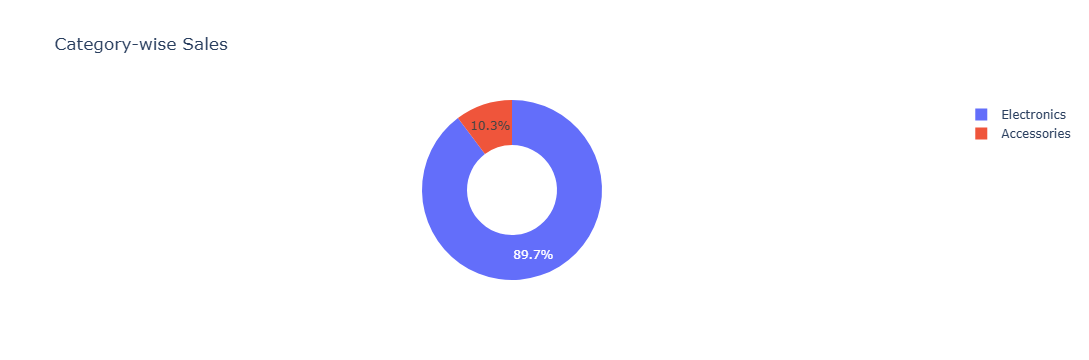

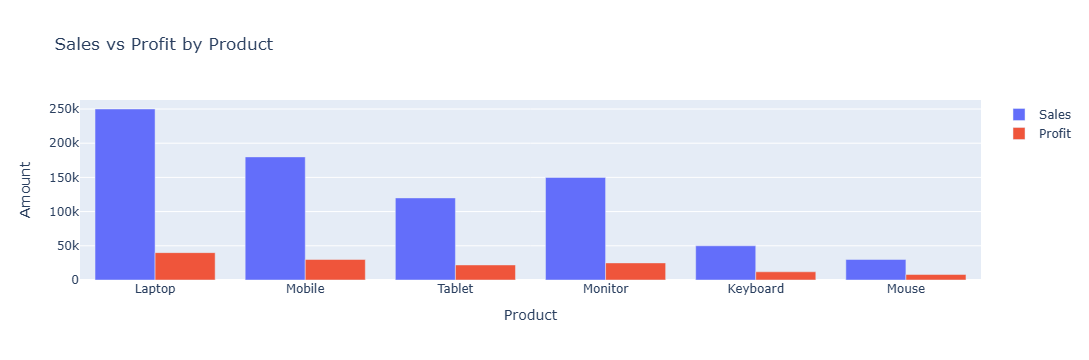

In [1]:
import pandas as pd
import plotly.graph_objects as go


# =========================================================
# DATA
# =========================================================

df = pd.DataFrame({
    "Product": ["Laptop", "Mobile", "Tablet", "Monitor", "Keyboard", "Mouse"],
    "Category": [
        "Electronics", "Electronics", "Electronics",
        "Electronics", "Accessories", "Accessories"
    ],
    "Sales": [250000, 180000, 120000, 150000, 50000, 30000],
    "Profit": [40000, 30000, 22000, 25000, 12000, 8000],
    "Orders": [25, 40, 20, 30, 50, 60],
    "Customers": [20, 35, 18, 25, 45, 55]
})


# =========================================================
# 1. SALES BY PRODUCT — BAR CHART
# =========================================================

fig1 = go.Figure()

fig1.add_trace(
    go.Bar(
        x=df["Product"],
        y=df["Sales"],
        name="Sales"
    )
)

fig1.update_layout(
    title="Sales by Product",
    xaxis_title="Product",
    yaxis_title="Sales"
)

fig1.show()


# =========================================================
# 2. PROFIT BY PRODUCT — BAR CHART
# =========================================================

fig2 = go.Figure()

fig2.add_trace(
    go.Bar(
        x=df["Product"],
        y=df["Profit"],
        name="Profit"
    )
)

fig2.update_layout(
    title="Profit by Product",
    xaxis_title="Product",
    yaxis_title="Profit"
)

fig2.show()


# =========================================================
# 3. ORDERS BY PRODUCT — BAR CHART
# =========================================================

fig3 = go.Figure()

fig3.add_trace(
    go.Bar(
        x=df["Product"],
        y=df["Orders"],
        name="Orders"
    )
)

fig3.update_layout(
    title="Orders by Product",
    xaxis_title="Product",
    yaxis_title="Orders"
)

fig3.show()


# =========================================================
# 4. SALES VS PROFIT — SCATTER CHART
# =========================================================

fig4 = go.Figure()

fig4.add_trace(
    go.Scatter(
        x=df["Sales"],
        y=df["Profit"],
        mode="markers",
        name="Products"
    )
)

fig4.update_layout(
    title="Sales vs Profit",
    xaxis_title="Sales",
    yaxis_title="Profit"
)

fig4.show()


# =========================================================
# 5. CATEGORY-WISE SALES — DONUT CHART
# =========================================================

category_sales = (
    df.groupby("Category")["Sales"]
      .sum()
      .reset_index()
)

fig5 = go.Figure()

fig5.add_trace(
    go.Pie(
        labels=category_sales["Category"],
        values=category_sales["Sales"],
        hole=0.5,
        name="Sales"
    )
)

fig5.update_layout(
    title="Category-wise Sales"
)

fig5.show()


# =========================================================
# 6. SALES VS PROFIT — GROUPED BAR CHART
# =========================================================

fig6 = go.Figure()

fig6.add_trace(
    go.Bar(
        x=df["Product"],
        y=df["Sales"],
        name="Sales"
    )
)

fig6.add_trace(
    go.Bar(
        x=df["Product"],
        y=df["Profit"],
        name="Profit"
    )
)

fig6.update_layout(
    title="Sales vs Profit by Product",
    xaxis_title="Product",
    yaxis_title="Amount",
    barmode="group"
)

fig6.show()

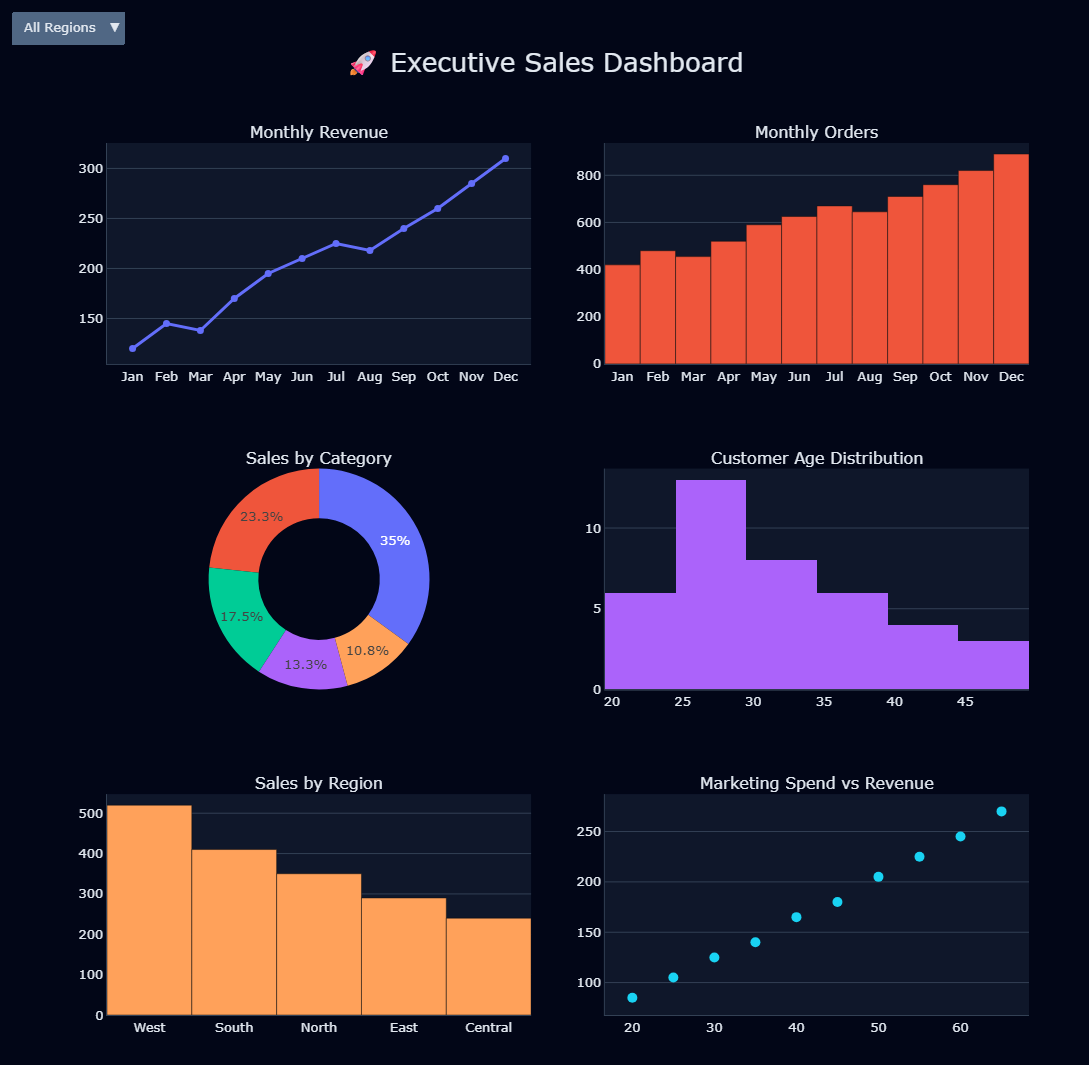

In [3]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# =========================================================
# 1. DUMMY DATA
# =========================================================

monthly = pd.DataFrame({
    "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    "Revenue": [120, 145, 138, 170, 195, 210,
                225, 218, 240, 260, 285, 310],
    "Orders": [420, 480, 455, 520, 590, 625,
               670, 645, 710, 760, 820, 890]
})

category = pd.DataFrame({
    "Category": ["Electronics", "Clothing", "Home", "Beauty", "Sports"],
    "Sales": [420, 280, 210, 160, 130]
})

age_data = pd.DataFrame({
    "Age": [
        21, 22, 24, 25, 26, 27, 28, 29, 30, 31,
        22, 24, 25, 27, 29, 32, 33, 35, 36, 38,
        23, 26, 28, 30, 31, 34, 37, 40, 42, 45,
        25, 27, 29, 32, 35, 39, 41, 44, 46, 48
    ]
})

region = pd.DataFrame({
    "Region": ["West", "South", "North", "East", "Central"],
    "Sales": [520, 410, 350, 290, 240]
})

marketing = pd.DataFrame({
    "Marketing_Spend": [20, 25, 30, 35, 40, 45, 50, 55, 60, 65],
    "Revenue": [85, 105, 125, 140, 165, 180, 205, 225, 245, 270]
})


# =========================================================
# 2. DASHBOARD
# =========================================================

fig = make_subplots(
    rows=3,
    cols=2,

    subplot_titles=(
        "Monthly Revenue",
        "Monthly Orders",
        "Sales by Category",
        "Customer Age Distribution",
        "Sales by Region",
        "Marketing Spend vs Revenue"
    ),

    specs=[
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "domain"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}]
    ],

    vertical_spacing=0.12,
    horizontal_spacing=0.08
)


# =========================================================
# 3. MONTHLY REVENUE
# =========================================================

fig.add_trace(
    go.Scatter(
        x=monthly["Month"],
        y=monthly["Revenue"],
        mode="lines+markers",
        name="Revenue",
        line=dict(width=3),
        marker=dict(size=7),
        hovertemplate="Month: %{x}<br>Revenue: %{y}K<extra></extra>"
    ),
    row=1,
    col=1
)


# =========================================================
# 4. MONTHLY ORDERS
# =========================================================

fig.add_trace(
    go.Bar(
        x=monthly["Month"],
        y=monthly["Orders"],
        name="Orders",
        hovertemplate="Month: %{x}<br>Orders: %{y}<extra></extra>"
    ),
    row=1,
    col=2
)


# =========================================================
# 5. DONUT CHART
# =========================================================

fig.add_trace(
    go.Pie(
        labels=category["Category"],
        values=category["Sales"],
        hole=0.55,
        textinfo="percent",
        hovertemplate="%{label}<br>Sales: %{value}K<extra></extra>"
    ),
    row=2,
    col=1
)


# =========================================================
# 6. AGE HISTOGRAM
# =========================================================

fig.add_trace(
    go.Histogram(
        x=age_data["Age"],
        nbinsx=8,
        name="Age",
        hovertemplate="Age: %{x}<br>Customers: %{y}<extra></extra>"
    ),
    row=2,
    col=2
)


# =========================================================
# 7. REGION SALES
# =========================================================

fig.add_trace(
    go.Bar(
        x=region["Region"],
        y=region["Sales"],
        name="Region Sales",
        hovertemplate="Region: %{x}<br>Sales: %{y}K<extra></extra>"
    ),
    row=3,
    col=1
)


# =========================================================
# 8. MARKETING VS REVENUE
# =========================================================

fig.add_trace(
    go.Scatter(
        x=marketing["Marketing_Spend"],
        y=marketing["Revenue"],
        mode="markers",
        name="Marketing",
        marker=dict(size=10),
        hovertemplate="Marketing: %{x}K<br>Revenue: %{y}K<extra></extra>"
    ),
    row=3,
    col=2
)


# =========================================================
# 9. DASHBOARD DESIGN
# =========================================================

fig.update_layout(

    title=dict(
        text="🚀 Executive Sales Dashboard",
        x=0.5,
        xanchor="center",
        font=dict(size=26)
    ),

    width=1400,
    height=1050,

    template="plotly_dark",

    plot_bgcolor="#0F172A",
    paper_bgcolor="#020617",

    font=dict(
        color="#E2E8F0",
        size=13
    ),

    showlegend=False,

    margin=dict(
        l=60,
        r=60,
        t=100,
        b=50
    )
)


# =========================================================
# 10. AXIS DESIGN
# =========================================================

fig.update_xaxes(
    showgrid=False,
    showline=True,
    linecolor="#334155"
)

fig.update_yaxes(
    showgrid=True,
    gridcolor="#334155",
    showline=True,
    linecolor="#334155"
)

fig.update_layout(
    updatemenus=[
        dict(
            buttons=[
                dict(
                    label="All Regions",
                    method="update",
                    args=[{"visible": [True]}]
                ),
                dict(
                    label="West",
                    method="update",
                    args=[{"visible": [True]}]
                ),
                dict(
                    label="South",
                    method="update",
                    args=[{"visible": [True]}]
                ),
                dict(
                    label="North",
                    method="update",
                    args=[{"visible": [True]}]
                )
            ],
            direction="down",
            showactive=True,
            x=0.02,
            y=1.15
        )
    ]
)


fig.show()